# 10. Serce, EEG i czujność na lapsach i 1/RT (COG-BCI, zadanie PVT)

Zadanie B10 z `docs/zadania.md` (COULD, issue #22). Notebook 05 pokazał, że w 10-minutowym PVT RMSSD (krótkoterminowa
zmienność rytmu serca z EKG) wiąże się z czasem reakcji: mediana korelacji wewnątrz osoby r = −0,23, kierunek ujemny
u 16 z 16 osób. Tam miarą zachowania była **mediana czasu reakcji** w minucie. Basner i Dinges (2011) pokazują, że średni
i medianowy RT to najmniej czułe miary PVT, a zalecają **lapsy** (RT > 500 ms) i **szybkość odpowiedzi 1/RT**
(`docs/podstawy-naukowe.md` §5).

**Pytania:**
1. Czy zdanie „RMSSD niesie własną informację o czujności (r = −0,23, ujemne u 16/16)” przetrwa, gdy miarą jest 1/RT i lapsy?
2. Czy RMSSD dodaje coś ponad **czas zadania**? W 10-minutowym PVT czujność spada z czasem, a RMSSD też może dryfować,
   więc wspólny trend sam z siebie daje korelację. Sprawdzamy korelację częściową z kontrolą numeru odcinka.
3. Przy okazji: dokumentujemy, że pliki `behavioral/PVT.mat` w COG-BCI nie należą do swoich nagrań (wykryte w notebooku 06).

**Dane i przetwarzanie** są takie jak w notebooku 05 (te same funkcje i reguły jakości): COG-BCI (Hinss i in., Zenodo 7413650),
PVT ok. 10 min, 90 bodźców; EEG na naszych 8 kanałach, referencja Fp1, 1–40 Hz, 250 Hz, okna 2 s z krokiem 1 s,
odrzucenie okien > 300 µV; załamki R z kanału `ECG1` (`neurokit2`), odstęp R–R poza 300–2000 ms lub odbiegający o > 20%
od lokalnej mediany = artefakt; odcinki 60 s. Czasy reakcji ze znaczników EEG (13 = bodziec, 14 = reakcja, 12 = błąd w przerwie).
**Falstarty** traktujemy jak w notebooku 06: reakcja < 100 ms i znacznik 12 nie wchodzą do RT.

**Miary zachowania w każdym odcinku 60 s** (ok. 9 prób):

| Miara | Definicja | Rola |
|---|---|---|
| szybkość 1/RT | średnia z 1/RT, RT w sekundach [1/s] | główna (Basner i Dinges 2011) |
| odsetek lapsów | lapsy (RT > 500 ms) / liczba prób | główna |
| mediana RT | jak w notebooku 05 | porównanie ze starym wynikiem |
| średni RT, odsetek RT > 355 ms | próg PVT-B (Basner i in. 2011) | tylko pomocniczo |

**Zasady analizy:** jednostką jest **osoba**. Korelację Spearmana liczymy w każdym nagraniu osobno (ok. 10 odcinków),
uśredniamy sesje danej osoby (transformacja Fishera), a potem patrzymy na rozkład po osobach: mediana, IQR, liczba osób
z oczekiwanym znakiem, test Wilcoxona względem zera, 95% przedział ufności mediany z bootstrapu po osobach. Odcinków różnych
nagrań nigdy nie wrzucamy do jednego worka. Trzy wersje korelacji: surowa, bez trendu (jak w 05: z obu miar usuwamy liniowy
trend w czasie) i częściowa (korelacja rang z kontrolą numeru odcinka).

**Ważne:** EKG z elektrod na klatce piersiowej w laboratorium to **nie jest** PPG z nadgarstka w zegarku.

In [ ]:
%pip install -q mne remotezip neurokit2

In [2]:
import shutil
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import neurokit2 as nk
import numpy as np
import pandas as pd
from remotezip import RemoteZip
from scipy.io import loadmat
from scipy.signal import welch
from scipy.stats import rankdata, spearmanr, wilcoxon

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

# --- identical to notebook 05 (product-like pipeline, ECG artefact rules, segment rules) ---
OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 250
WIN_S, STEP_S = 2.0, 1.0
REJECT_UV = 300                 # drop 2 s windows whose peak-to-peak exceeds this (any channel)
SEG_S = 60                      # PVT segment length
BANDS = {"theta": (4, 7), "alpha": (8, 12), "beta": (13, 30)}
RR_MIN, RR_MAX = 300, 2000      # plausible RR interval range [ms] (30-200 bpm)
RR_JUMP = 0.20                  # RR deviating > 20 % from the local median = artefact / missed or extra beat
MIN_SEGMENTS = 8                # a recording needs this many valid segments to enter correlations
# --- behavioural outcomes (Basner & Dinges 2011) ---
LAPSE_MS = 500                  # classic PVT lapse
LAPSE_B_MS = 355                # PVT-B lapse threshold, sensitivity only
FALSE_START_MS = 100            # RT < 100 ms = anticipation / false start (as in notebook 06)
MIN_LAPSES_REC = 3              # a recording enters lapse correlations only with >= 3 lapses
N_BOOT = 5000

SUBJECTS = [f"sub-{i:02d}" for i in range(1, 30)]
SUBJECTS_05 = [f"sub-{i:02d}" for i in range(1, 17)]   # the 16 people of notebook 05
SESSIONS = ["S1", "S2", "S3"]
PVT_CODES = {"11", "12", "13", "14", "15"}   # trial/ISI start, ISI error (false start), stimulus, response, end

DATA = Path("/content/data") if Path("/content").exists() else Path.home() / ".cache" / "wachta-eeg"
RAW_DIR = DATA / "cogbci-pvt-b10"            # extracted .set/.fdt, deleted after each subject
RES_DIR = DATA / "cogbci-pvt-b10-results"    # small per-recording tables, kept so re-runs skip downloads
CACHE_05 = DATA / "cogbci-pvt-results"       # notebook 05 cache (same functions), reused if present
CACHE_06 = DATA / "cogbci-pvt-b5-results"    # notebook 06 cache (PVT trigger tables), reused if present
RES_DIR.mkdir(parents=True, exist_ok=True)
COG_URL = "https://zenodo.org/records/7413650/files/{sub}.zip?download=1"

## 1. Pobranie PVT i tabele na nagranie

Z każdego archiwum (~1,1 GB na osobę) wyciągamy przez zapytania HTTP z zakresem (`remotezip`) tylko `PVT.set` i `PVT.fdt`
(~77 MB na sesję), dopasowując pliki po końcówce ścieżki (układ folderów różni się między osobami). Liczymy trzy małe tabele
na nagranie (znaczniki PVT, odstępy R–R z flagą artefaktu, wskaźniki EEG w odcinkach 60 s) i od razu kasujemy surowe pliki.
Tabele zostają w katalogu cache poza repo.

Jeśli na dysku są już cache notebooków 05 (EEG w odcinkach i R–R, osoby 1–16) i 06 (znaczniki PVT, osoby 1–29), bierzemy je zamiast
pobierać drugi raz: liczyły je te same funkcje. Przy budowie tego notebooka sprawdziliśmy to na `sub-01 S1` przeliczonym od zera
(identyczne wartości). Bez żadnego cache (np. w Colab) wszystko pobiera się i liczy od nowa: ok. 2–3 min na osobę.

In [3]:
def eeg_windows(raw):
    """Notebook 05 pipeline on our 8 channels: Fp1 reference, 1-40 Hz, 250 Hz, 2 s windows / 1 s step."""
    r = raw.copy()
    r.set_eeg_reference(["Fp1"], projection=False)       # BrainAccess MINI: hardware reference at Fp1
    r.pick(OUR_CH).reorder_channels(OUR_CH)
    r.filter(1.0, 40.0, fir_design="firwin", verbose=False).resample(FS)
    ep = mne.make_fixed_length_epochs(r, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)
    x = ep.get_data()
    ptp = np.ptp(x, axis=-1).max(1) * 1e6
    f, p = welch(x, FS, nperseg=int(WIN_S * FS), axis=-1)
    p = p * 1e12
    dfh = f[1] - f[0]
    pw = {b: p[:, :, (f >= lo) & (f <= hi)].sum(-1) * dfh for b, (lo, hi) in BANDS.items()}
    po = p[:, 6:8].mean(1)                                    # O1/O2 mean PSD
    band = lambda lo, hi: po[:, (f >= lo) & (f <= hi)].mean(1)
    return pd.DataFrame({
        "t": ep.events[:, 0] / FS,
        "alpha_occ": np.log10(pw["alpha"][:, 6:8].mean(1)),
        "tab_ratio": np.log10((pw["theta"].mean(1) + pw["alpha"].mean(1)) / pw["beta"].mean(1)),
        "alpha_prom": np.log10(band(8, 12) / np.sqrt(band(5, 7) * band(14, 16))),
        "bad": ptp > REJECT_UV,
    })


def r_peaks(raw):
    """Cleaned ECG (µV) and R-peak times (s); same detector and settings as notebook 05."""
    fs = raw.info["sfreq"]
    ecg = raw.copy().pick(["ECG1"]).get_data()[0] * 1e6
    clean = nk.ecg_clean(ecg, sampling_rate=fs, method="neurokit")
    med = np.median(clean)
    if med - np.percentile(clean, 0.5) > np.percentile(clean, 99.5) - med:
        clean = -clean                                        # inverted lead: make R waves positive
    _, info = nk.ecg_peaks(clean, sampling_rate=fs, method="neurokit", correct_artifacts=False)
    return np.asarray(info["ECG_R_Peaks"]) / fs


def rr_table(peaks_s):
    rr = np.diff(peaks_s) * 1000
    med = pd.Series(rr).rolling(11, center=True, min_periods=3).median().values
    ok = (rr >= RR_MIN) & (rr <= RR_MAX) & (np.abs(rr - med) <= RR_JUMP * med)
    return pd.DataFrame({"t": peaks_s[1:], "rr": rr, "ok": ok})


def task_bounds(ev):
    """Task start = first trial start (11), end = task end (15), as in notebook 05."""
    code, on = ev.code.astype(str).values, ev.onset.values
    t0 = on[code == "11"][0] if (code == "11").any() else on[code == "13"][0]
    t1 = on[code == "15"][0] if (code == "15").any() else on.max()
    return t0, t1


def eeg_segments(W, t0, t1):
    rows = []
    for k in range(int((t1 - t0) // SEG_S)):
        a, b = t0 + k * SEG_S, t0 + (k + 1) * SEG_S
        w = W[(W.t >= a) & (W.t + WIN_S <= b)]
        wk = w[~w.bad]
        rows.append(dict(seg=k, t_min=k * SEG_S / 60, n_win=len(w), n_clean=len(wk), alpha_occ=wk.alpha_occ.mean(),
                         tab_ratio=wk.tab_ratio.mean(), alpha_prom=wk.alpha_prom.mean()))
    return pd.DataFrame(rows)


def files(sub, ses):
    return {k: RES_DIR / f"{sub}_{ses}_{k}.csv" for k in ("events", "rr", "eegseg")}


def done(sub, ses):
    return all(p.exists() for p in files(sub, ses).values())


def reuse_cache(sub, ses):
    """Notebooks 05 and 06 computed exactly these tables with the same code; reuse them instead of re-downloading."""
    seg05, rr05, ev06 = (CACHE_05 / f"{sub}_{ses}_seg.csv", CACHE_05 / f"{sub}_{ses}_rr.csv",
                         CACHE_06 / f"{sub}_{ses}_events.csv")
    if not (seg05.exists() and rr05.exists() and ev06.exists()):
        return False
    f = files(sub, ses)
    pd.read_csv(ev06, dtype={"code": str}).to_csv(f["events"], index=False)
    pd.read_csv(rr05)[["t", "rr", "ok"]].to_csv(f["rr"], index=False)
    pd.read_csv(seg05)[["seg", "t_min", "n_win", "n_clean", "alpha_occ", "tab_ratio", "alpha_prom"]].to_csv(
        f["eegseg"], index=False)
    return True


def process_raw(raw, sub, ses):
    f = files(sub, ses)
    ann = pd.DataFrame({"onset": raw.annotations.onset, "code": raw.annotations.description})
    ev = ann[ann.code.isin(PVT_CODES)].reset_index(drop=True)
    t0, t1 = task_bounds(ev)
    eeg_segments(eeg_windows(raw), t0, t1).to_csv(f["eegseg"], index=False)
    rr_table(r_peaks(raw)).to_csv(f["rr"], index=False)
    ev.to_csv(f["events"], index=False)                   # written last: marks the recording as complete


def fetch_and_process(sub, retries=5):
    """Range-request only PVT.set/.fdt of one subject (layouts differ, so match by path suffix), then delete them."""
    todo = [s for s in SESSIONS if not done(sub, s) and not reuse_cache(sub, s)]
    if not todo:
        return "cache"
    for attempt in range(retries):
        try:
            with RemoteZip(COG_URL.format(sub=sub)) as z:
                for n in z.namelist():
                    if n.endswith(("/eeg/PVT.set", "/eeg/PVT.fdt")) and "/ses-" in n and n.split("/ses-")[1][:2] in todo:
                        z.extract(n, RAW_DIR / sub)
            break
        except Exception as e:                            # Zenodo rate limits / network hiccups: back off
            wait = 60 * 2 ** attempt
            print(f"  {sub}: próba {attempt + 1} nieudana ({type(e).__name__}); czekam {wait} s")
            shutil.rmtree(RAW_DIR / sub, ignore_errors=True)
            time.sleep(wait)
    for path in sorted((RAW_DIR / sub).rglob("ses-*/eeg/PVT.set")):
        ses = path.parent.parent.name[4:]
        try:
            process_raw(mne.io.read_raw_eeglab(path, preload=True), sub, ses)
        except Exception as e:
            print(f"  {sub} {ses}: błąd obróbki ({type(e).__name__}: {e})")
    shutil.rmtree(RAW_DIR / sub, ignore_errors=True)
    return "downloaded"

In [4]:
t_start = time.time()
for sub in SUBJECTS:
    status = fetch_and_process(sub)
    if status != "cache":
        print(f"{sub}: pobrane ({time.time() - t_start:.0f} s od startu)")
missing = [f"{s} {ses}" for s in SUBJECTS for ses in SESSIONS if not done(s, ses)]
print("gotowe; brakujące nagrania:", missing or "brak")

gotowe; brakujące nagrania: brak


## 2. Pliki `behavioral/PVT.mat` nie należą do swoich nagrań

Spis archiwum zip podaje sumę kontrolną CRC-32 każdego pliku, więc zgodność plików sprawdzamy bez pobierania.
Potem pobieramy kilka małych plików `PVT.mat` (3 kB) i porównujemy je z próbami odczytanymi ze znaczników EEG tego samego nagrania:
czasy reakcji i przerwy przed bodźcem (ISI, od znacznika 11 do 13). Dla każdego pliku szukamy też najlepiej pasującego
nagrania wśród wszystkich 87.

In [5]:
MAT_DIR = RES_DIR / "pvtmat"          # tiny behavioral/PVT.mat files (3 kB each)
MAT_DIR.mkdir(exist_ok=True)
CRC_FILE = RES_DIR / "pvtmat_crc.csv"
MAT_EXAMPLES = [("sub-01", "S1"), ("sub-01", "S2"), ("sub-01", "S3"), ("sub-02", "S1"), ("sub-03", "S1"), ("sub-17", "S1")]


def zip_retry(sub, fn, retries=5):
    for attempt in range(retries):
        try:
            with RemoteZip(COG_URL.format(sub=sub)) as z:
                return fn(z)
        except Exception as e:
            wait = 60 * 2 ** attempt
            print(f"  {sub}: próba {attempt + 1} nieudana ({type(e).__name__}); czekam {wait} s")
            time.sleep(wait)
    raise RuntimeError(f"{sub}: Zenodo niedostępne")


if CRC_FILE.exists():
    crc = pd.read_csv(CRC_FILE)
else:   # the zip's central directory holds a CRC-32 of every file, so nothing has to be downloaded for this check
    crc = []
    for sub in SUBJECTS:
        crc += zip_retry(sub, lambda z: [(sub, i.filename.split("/ses-")[1][:2], i.CRC, i.file_size, i.filename)
                                         for i in z.infolist() if i.filename.endswith("behavioral/PVT.mat")])
    crc = pd.DataFrame(crc, columns=["subject", "session", "crc32", "bytes", "path"])
    crc.to_csv(CRC_FILE, index=False)
print(crc.groupby(["crc32", "bytes"]).size().rename("liczba plików").to_string())
print(f"\nróżnych plików PVT.mat wśród {len(crc)}: {crc.crc32.nunique()}")
print("pierwsze wystąpienie każdego pliku:", crc.groupby("crc32").first()[["subject", "session"]].to_dict("index"))

for sub, ses in MAT_EXAMPLES:
    out = MAT_DIR / f"{sub}_{ses}_PVT.mat"
    if not out.exists():
        name = crc[(crc.subject == sub) & (crc.session == ses)].path.iloc[0]
        zip_retry(sub, lambda z: out.write_bytes(z.read(name)))

crc32       bytes
1922564557  2988     24
2782752299  2988     63

różnych plików PVT.mat wśród 87: 2
pierwsze wystąpienie każdego pliku: {1922564557: {'subject': 'sub-17', 'session': 'S1'}, 2782752299: {'subject': 'sub-01', 'session': 'S1'}}


In [6]:
def mat_pvt(path):
    s = loadmat(path)["PVT"][0, 0]
    return np.ravel(s["reaction_times"]) * 1000, np.ravel(s["isi_time"])


def trigger_pvt(sub, ses):
    """Per-trial RT (ms, no exclusions) and ISI (s, trial start 11 -> stimulus 13) from the EEG triggers."""
    ev = pd.read_csv(files(sub, ses)["events"], dtype={"code": str})
    on, code = ev.onset.values, ev.code.values
    rt, isi = [], []
    for s in on[code == "13"]:
        r = on[(code == "14") & (on >= s)]
        rt.append((r[0] - s) * 1000 if len(r) else np.nan)
        isi.append(s - on[(code == "11") & (on < s)].max())
    return np.array(rt), np.array(isi)


def r_ok(a, b):
    m = ~(np.isnan(a) | np.isnan(b))
    return np.corrcoef(a[m], b[m])[0, 1]


TRIG = {(s, ses): trigger_pvt(s, ses) for s in SUBJECTS for ses in SESSIONS if done(s, ses)}
rows = []
for sub, ses in MAT_EXAMPLES:
    rt_m, isi_m = mat_pvt(MAT_DIR / f"{sub}_{ses}_PVT.mat")
    rt_t, isi_t = TRIG[sub, ses]
    best = max(TRIG, key=lambda k: r_ok(rt_m, TRIG[k][0]) if len(TRIG[k][0]) == len(rt_m) else -1)
    rows.append(dict(nagranie=f"{sub} {ses}", crc32=int(crc[(crc.subject == sub) & (crc.session == ses)].crc32.iloc[0]),
                     n_mat=len(rt_m), n_trig=len(rt_t),
                     mediana_RT_mat=np.median(rt_m), mediana_RT_trig=np.nanmedian(rt_t),
                     r_RT_mat_vs_trig=r_ok(rt_m, rt_t), r_ISI_mat_vs_trig=r_ok(isi_m, isi_t),
                     najlepsze_z_87=" ".join(best), r_RT_najlepsze=r_ok(rt_m, TRIG[best][0]),
                     r_ISI_najlepsze=r_ok(isi_m, TRIG[best][1]),
                     max_roznica_RT_ms=np.nanmax(np.abs(rt_m - TRIG[best][0])),
                     max_roznica_ISI_ms=1000 * np.nanmax(np.abs(isi_m - TRIG[best][1]))))
MAT = pd.DataFrame(rows)
a, b = (mat_pvt(MAT_DIR / f"{s}_{ses}_PVT.mat") for s, ses in [MAT_EXAMPLES[0], MAT_EXAMPLES[-1]])
print("oba warianty pliku (różne CRC) mają identyczne RT i ISI:", np.allclose(a[0], b[0]) and np.allclose(a[1], b[1]))
others = [r_ok(a[0], v[0]) for k, v in TRIG.items() if k != tuple(MAT.najlepsze_z_87[0].split())]
print(f"korelacja RT z pozostałymi 86 nagraniami: mediana {np.median(others):+.2f}, maks. {max(others):+.2f}")
MAT.round(3)

oba warianty pliku (różne CRC) mają identyczne RT i ISI: True
korelacja RT z pozostałymi 86 nagraniami: mediana -0.00, maks. +0.23


,nagranie,crc32,n_mat,n_trig,mediana_RT_mat,mediana_RT_trig,r_RT_mat_vs_trig,r_ISI_mat_vs_trig,najlepsze_z_87,r_RT_najlepsze,r_ISI_najlepsze,max_roznica_RT_ms,max_roznica_ISI_ms
0,sub-01 S1,2782752299,90,90,350.5,304.0,-0.108,-0.030,sub-29 S3,1.0,1.0,10.0,4.801
1,sub-01 S2,2782752299,90,90,350.5,306.0,0.100,0.032,sub-29 S3,1.0,1.0,10.0,4.801
2,sub-01 S3,2782752299,90,90,350.5,286.0,-0.017,-0.108,sub-29 S3,1.0,1.0,10.0,4.801
3,sub-02 S1,2782752299,90,90,350.5,357.0,-0.033,0.040,sub-29 S3,1.0,1.0,10.0,4.801
4,sub-03 S1,2782752299,90,90,350.5,298.0,-0.117,0.109,sub-29 S3,1.0,1.0,10.0,4.801
5,sub-17 S1,1922564557,90,90,350.5,323.0,-0.023,0.055,sub-29 S3,1.0,1.0,10.0,4.801


**Wynik: wszystkie 87 plików `behavioral/PVT.mat` to kopie zachowania z jednego nagrania.**

- W 87 folderach (29 osób × 3 sesje) są tylko **2 różne pliki** (różne sumy CRC, 24 i 63 kopie). Oba warianty mają
  **identyczne** czasy reakcji i przerwy ISI, więc różnią się tylko metadanymi.
- Dla sprawdzonych nagrań (`sub-01` S1–S3, `sub-02` S1, `sub-03` S1, `sub-17` S1) czasy reakcji z `.mat` nie korelują
  z czasami ze znaczników EEG tego samego nagrania (r od −0,12 do +0,10), a przerwy ISI też nie (r od −0,11 do +0,11).
  Mediana RT w `.mat` jest wszędzie ta sama (350,5 ms), a ze znaczników waha się od 286 do 357 ms.
- Wśród wszystkich 87 nagrań plik pasuje idealnie do **jednego: `sub-29` S3** (r = 1,0 dla RT i dla ISI; różnice do 10 ms w RT
  i do 5 ms w ISI, czyli rozdzielczość znaczników). Z pozostałymi 86 nagraniami korelacja RT ma medianę 0,00 (maks. 0,23).

**Konsekwencja:** kto liczy czasy reakcji PVT w COG-BCI z plików `PVT.mat`, dostaje dla każdej osoby i sesji zachowanie
osoby `sub-29` z sesji S3. Wnioski o związku EEG lub serca z RT oparte na tych plikach byłyby bez sensu. Dlatego tutaj
(jak w notebookach 05 i 06) RT bierzemy wyłącznie ze znaczników 13/14 w zapisie EEG. Sprawdziliśmy tylko plik PVT;
pliki behawioralne innych zadań w COG-BCI mogą mieć ten sam problem. **Warto to zgłosić autorom zbioru** (Hinss i in.,
rekord Zenodo 7413650): „behavioral/PVT.mat is identical in content across all 87 subject/session folders and matches
the EEG triggers of sub-29 ses-S3 only”.

## 3. Odcinki 60 s: serce, EEG i zachowanie

Serce (HR, RMSSD, SDNN) liczymy z odstępów R–R dokładnie jak w notebooku 05 (RMSSD tylko z par sąsiednich poprawnych odstępów).
Zachowanie: próby, których bodziec wypadł w danym odcinku. Liczymy też medianę RT według reguły z notebooka 05 (bez wyłączania
falstartów), żeby odtworzyć stary wynik.

In [7]:
def trials_06(ev):
    """Notebook 06 rule: stimulus (13) + first response (14) before the next stimulus = one trial.
    RT < 100 ms (response logged with the stimulus) = false start: RT set to NaN, excluded.
    ISI-error triggers (12, key pressed before the stimulus) belong to no stimulus, so they never enter RT."""
    on, code = ev.onset.values, ev.code.astype(str).values
    stim, resp = on[code == "13"], on[code == "14"]
    rows = []
    for i, s in enumerate(stim):
        nxt = stim[i + 1] if i + 1 < len(stim) else np.inf
        r = resp[(resp >= s) & (resp < nxt)]
        rows.append((s, (r[0] - s) * 1000 if len(r) else np.nan))
    tr = pd.DataFrame(rows, columns=["t", "rt_ms"])
    tr["false_start"] = tr.rt_ms < FALSE_START_MS
    tr.loc[tr.false_start, "rt_ms"] = np.nan
    return tr


def trials_05(ev):
    """Notebook 05 rule (kept only to reproduce its result): no false-start exclusion."""
    on, code = ev.onset.values, ev.code.astype(str).values
    stim, resp = on[code == "13"], on[code == "14"]
    rows = []
    for s in stim:
        nxt, nxt_stim = resp[resp > s], stim[stim > s]
        if len(nxt) and (not len(nxt_stim) or nxt[0] < nxt_stim[0]):
            rows.append((s, (nxt[0] - s) * 1000))
    return pd.DataFrame(rows, columns=["t", "rt_ms"])


def heart_segment(R, a, b):
    """Identical to notebook 05: HR from clean RR, RMSSD only from pairs of adjacent clean RR."""
    s = R[(R.t >= a) & (R.t < b)]
    good = s[s.ok]
    pair_ok = s.ok.values[1:] & s.ok.values[:-1]
    d = np.diff(s.rr.values)[pair_ok]
    return dict(hr=60000 / good.rr.mean() if len(good) else np.nan,
                rmssd=np.sqrt(np.mean(d ** 2)) if len(d) > 10 else np.nan,
                sdnn=good.rr.std() if len(good) > 10 else np.nan,
                rr_bad_frac=1 - s.ok.mean() if len(s) else np.nan)


def segment_table(sub, ses):
    f = files(sub, ses)
    ev = pd.read_csv(f["events"], dtype={"code": str})
    R = pd.read_csv(f["rr"])
    E = pd.read_csv(f["eegseg"])
    t0, t1 = task_bounds(ev)
    tr, tr5 = trials_06(ev), trials_05(ev)
    isi12 = ev.onset[ev.code == "12"].values
    rows = []
    for k in E.seg:
        a, b = t0 + k * SEG_S, t0 + (k + 1) * SEG_S
        t = tr[(tr.t >= a) & (tr.t < b)]
        rt = t.rt_ms.dropna()
        t5 = tr5[(tr5.t >= a) & (tr5.t < b)]
        row = dict(subject=sub, session=ses, seg=k,
                   n_trials=len(rt), n_false=int(t.false_start.sum() + ((isi12 >= a) & (isi12 < b)).sum()),
                   speed=(1000 / rt).mean() if len(rt) else np.nan,           # mean 1/RT [1/s]
                   lapses=int((rt > LAPSE_MS).sum()),
                   lapse_rate=(rt > LAPSE_MS).mean() if len(rt) else np.nan,
                   lapse355_rate=(rt > LAPSE_B_MS).mean() if len(rt) else np.nan,
                   rt_med=rt.median() if len(rt) else np.nan,
                   rt_mean=rt.mean() if len(rt) else np.nan,
                   rt_med_05=t5.rt_ms.median() if len(t5) else np.nan, n_trials_05=len(t5))
        row.update(heart_segment(R, a, b))
        rows.append(row)
    return E.merge(pd.DataFrame(rows), on="seg")


SEG = pd.concat([segment_table(s, ses) for s in SUBJECTS for ses in SESSIONS if done(s, ses)], ignore_index=True)
SEG["rec"] = SEG.subject + "_" + SEG.session
print(f"{SEG.subject.nunique()} osób, {SEG.rec.nunique()} nagrań PVT, {len(SEG)} odcinków 60 s")
per_rec = SEG.groupby("rec").agg(n_trials=("n_trials", "sum"), n_false=("n_false", "sum"), lapses=("lapses", "sum"))
print(f"próby z RT na nagranie: mediana {per_rec.n_trials.median():.0f}; falstarty razem {per_rec.n_false.sum()}; "
      f"lapsy > 500 ms razem {per_rec.lapses.sum()}, na nagranie mediana {per_rec.lapses.median():.0f} "
      f"[{per_rec.lapses.min()}–{per_rec.lapses.max()}], nagrania bez lapsu: {(per_rec.lapses == 0).sum()}")

29 osób, 87 nagrań PVT, 862 odcinków 60 s
próby z RT na nagranie: mediana 86; falstarty razem 66; lapsy > 500 ms razem 189, na nagranie mediana 1 [0–14], nagrania bez lapsu: 26


Reguły dopuszczenia z notebooka 05: odcinek ma co najmniej 20 czystych okien EEG, co najwyżej 10% odrzuconych odstępów R–R
i co najmniej 3 próby z ważnym RT; nagranie wchodzi do korelacji, gdy ma co najmniej 8 dopuszczonych odcinków.
Korelacje z odsetkiem lapsów liczymy tylko w nagraniach z co najmniej 3 lapsami: przy zerze lapsów korelacja nie istnieje,
a przy jednym-dwóch zależy od pojedynczej próby.

In [8]:
# notebook 05 admission rules; "trials" = valid RTs (false starts excluded)
SEG["valid"] = (SEG.n_clean >= 20) & (SEG.rr_bad_frac <= 0.10) & (SEG.n_trials >= 3) & SEG.rmssd.notna()
nvalid = SEG.groupby("rec").valid.sum()
good_recs = nvalid[nvalid >= MIN_SEGMENTS].index
V = SEG[SEG.valid & SEG.rec.isin(good_recs)].copy()
print(f"odcinki dopuszczone: {SEG.valid.sum()} z {len(SEG)}")
print(f"nagrania w analizie: {len(good_recs)} z {SEG.rec.nunique()}, osoby: {V.subject.nunique()}, odcinki: {len(V)}")
print("odrzucone nagrania:", sorted(set(SEG.rec) - set(good_recs)))
lap = V.groupby("rec").lapses.sum()
lap_recs = lap[lap >= MIN_LAPSES_REC].index
print(f"lapsy > 500 ms w dopuszczonych odcinkach: {lap.sum()}; nagrania z >= {MIN_LAPSES_REC} lapsami: {len(lap_recs)} "
      f"(osoby: {V[V.rec.isin(lap_recs)].subject.nunique()}); odcinki z co najmniej 1 lapsem: {(V.lapses > 0).mean():.0%}")
print(f"szybkość 1/RT na odcinek: mediana {V.speed.median():.2f} 1/s [{V.speed.min():.2f}–{V.speed.max():.2f}]")

odcinki dopuszczone: 790 z 862
nagrania w analizie: 77 z 87, osoby: 29, odcinki: 743
odrzucone nagrania: ['sub-07_S2', 'sub-10_S3', 'sub-11_S1', 'sub-11_S3', 'sub-14_S1', 'sub-14_S2', 'sub-15_S2', 'sub-19_S1', 'sub-28_S2', 'sub-28_S3']
lapsy > 500 ms w dopuszczonych odcinkach: 152; nagrania z >= 3 lapsami: 19 (osoby: 12); odcinki z co najmniej 1 lapsem: 17%
szybkość 1/RT na odcinek: mediana 3.09 1/s [2.34–3.99]


## 4. Odtworzenie starego wyniku

Najpierw funkcje korelacji (wewnątrz nagrania, potem po osobach). Potem te same 16 osób, reguły i miara co w notebooku 05
(mediana RT bez wyłączania falstartów). Wynik musi się zgadzać z liczbą na slajdzie.

In [9]:
def detrend(d, c):
    """Notebook 05: residuals of a linear fit on time within the recording."""
    y = d[c].values.astype(float)
    m = ~np.isnan(y)
    out = np.full_like(y, np.nan, dtype=float)
    if m.sum() > 3:
        out[m] = y[m] - np.polyval(np.polyfit(d.t_min.values[m], y[m], 1), d.t_min.values[m])
    return out


def partial_spearman(x, y, z):
    """Spearman partial correlation of x and y controlling for z (ranks, linear residuals)."""
    m = ~(np.isnan(x) | np.isnan(y) | np.isnan(z))
    if m.sum() < 5:
        return np.nan
    rx, ry, rz = rankdata(x[m]), rankdata(y[m]), rankdata(z[m])
    res = lambda v: v - np.polyval(np.polyfit(rz, v, 1), rz)
    ex, ey = res(rx), res(ry)
    if ex.std() < 1e-9 or ey.std() < 1e-9:
        return np.nan
    return np.corrcoef(ex, ey)[0, 1]


def rec_corrs(V, pairs, min_lapses=MIN_LAPSES_REC):
    """One row per recording and pair: raw, detrended and time-partialled Spearman r."""
    rows = []
    for rec, d in V.groupby("rec"):
        d = d.sort_values("t_min")
        lapse_ok = d.lapses.sum() >= min_lapses
        for a, b in pairs:
            if b in ("lapse_rate",) and not lapse_ok:
                continue
            x, y = d[a].values.astype(float), d[b].values.astype(float)
            sp = lambda u, v: spearmanr(u, v, nan_policy="omit").statistic if np.nanstd(u) > 0 and np.nanstd(v) > 0 else np.nan
            rows.append(dict(rec=rec, subject=d.subject.iloc[0], pred=a, outcome=b, n_seg=len(d),
                             r_raw=sp(x, y),
                             r_detr=sp(detrend(d, a), detrend(d, b)) if a != "t_min" else np.nan,
                             r_partial=partial_spearman(x, y, d.t_min.values.astype(float)) if a != "t_min" else np.nan))
    return pd.DataFrame(rows)


def to_person(RC, col):
    """Average a recording's correlations within a person (Fisher z), so the person is the unit."""
    zf = np.arctanh(RC[col].clip(-0.999, 0.999))
    return np.tanh(zf.groupby([RC.pred, RC.outcome, RC.subject]).mean())


def boot_median_ci(v, n=N_BOOT, seed=0):
    rng = np.random.default_rng(seed)
    meds = np.median(rng.choice(v, size=(n, len(v)), replace=True), axis=1)
    return np.percentile(meds, [2.5, 97.5])


# expected sign of r for "more vigilant" outcome (speed); flipped for lapses / RT. 0 = no prior direction.
EXPECT = {"rmssd": +1, "t_min": -1, "alpha_prom": -1, "alpha_occ": -1, "tab_ratio": -1, "hr": 0, "sdnn": 0}
OUT_SIGN = {"speed": +1, "lapse_rate": -1, "lapse355_rate": -1, "rt_med": -1, "rt_med_05": -1, "rt_mean": -1}


def summarise(RC, versions=("r_raw", "r_detr", "r_partial")):
    rows = []
    for col in versions:
        P = to_person(RC, col)
        for (a, b), v in P.groupby(level=[0, 1]):
            v = v.dropna().values
            if len(v) < 6:
                continue
            exp = EXPECT.get(a, 0) * OUT_SIGN.get(b, 0)
            lo, hi = boot_median_ci(v)
            rv = RC[(RC.pred == a) & (RC.outcome == b)][col].dropna().values
            rows.append(dict(pred=a, outcome=b, version=col, n_people=len(v), median_r=np.median(v),
                             q25=np.percentile(v, 25), q75=np.percentile(v, 75), ci_lo=lo, ci_hi=hi,
                             expected="+" if exp > 0 else "−" if exp < 0 else "?",
                             n_expected=f"{int((np.sign(v) == exp).sum())}/{len(v)}" if exp else f"{int((v > 0).sum())}/{len(v)} dodatnich",
                             p_wilcoxon=wilcoxon(v).pvalue, n_rec=len(rv),
                             rec_expected=f"{int((np.sign(rv) == exp).sum())}/{len(rv)}" if exp else f"{int((rv > 0).sum())}/{len(rv)}"))
    return pd.DataFrame(rows)


def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0
    for i, j in enumerate(order):
        running = max(running, (len(p) - i) * p[j])
        adj[j] = min(1.0, running)
    return adj

In [10]:
O = SEG[SEG.subject.isin(SUBJECTS_05)].copy()
O["valid"] = (O.n_clean >= 20) & (O.rr_bad_frac <= 0.10) & (O.n_trials_05 >= 3) & O.rmssd.notna()
nv5 = O.groupby("rec").valid.sum()
V05 = O[O.valid & O.rec.isin(nv5[nv5 >= MIN_SEGMENTS].index)]
print(f"definicja z notebooka 05: {V05.rec.nunique()} nagrań, {V05.subject.nunique()} osób, {len(V05)} odcinków")
RC05 = rec_corrs(V05, [("rmssd", "rt_med_05")])
OLD = summarise(RC05)
OLD.round(3)

definicja z notebooka 05: 41 nagrań, 16 osób, 393 odcinków


,pred,outcome,version,n_people,median_r,q25,q75,ci_lo,ci_hi,expected,n_expected,p_wilcoxon,n_rec,rec_expected
0,rmssd,rt_med_05,r_raw,16,-0.226,-0.266,-0.199,-0.263,-0.199,−,16/16,0.000,41,26/41
1,rmssd,rt_med_05,r_detr,16,-0.216,-0.365,-0.107,-0.364,-0.114,−,13/16,0.002,41,28/41
2,rmssd,rt_med_05,r_partial,16,-0.209,-0.251,-0.165,-0.250,-0.174,−,15/16,0.000,41,27/41


## 5. Korelacje wewnątrz osoby: wszystkie osoby, wszystkie miary

Kolumny: trzy wersje korelacji. W komórce: mediana r po osobach, [95% CI z bootstrapu], liczba osób ze znakiem oczekiwanym
i *p* testu Wilcoxona (bez korekty). Znak oczekiwany: RMSSD dodatnio z 1/RT i ujemnie z lapsami i RT (kierunek z notebooka 05);
wskaźniki EEG zmęczenia (alfa, (θ+α)/β) odwrotnie. Dla tętna i SDNN nie ma jednego oczekiwanego kierunku, więc podajemy liczbę
osób z korelacją dodatnią.

In [11]:
PRED = ["rmssd", "hr", "sdnn", "alpha_prom", "tab_ratio", "alpha_occ", "t_min"]
OUTS = ["speed", "lapse_rate", "rt_med", "rt_mean", "lapse355_rate"]
RC = rec_corrs(V, [(a, b) for a in PRED for b in OUTS] + [("t_min", "rmssd"), ("t_min", "hr")])
ALL = summarise(RC)
ALL["p_holm_all"] = holm(ALL.p_wilcoxon)        # Holm over every test in this table (exploratory family)
NAMES = {"rmssd": "RMSSD", "hr": "tętno", "sdnn": "SDNN", "alpha_prom": "wyrazistość alfy", "tab_ratio": "(θ+α)/β",
         "alpha_occ": "alfa O1/O2", "t_min": "czas zadania", "speed": "szybkość 1/RT", "lapse_rate": "odsetek lapsów",
         "rt_med": "mediana RT", "rt_mean": "średni RT", "lapse355_rate": "odsetek RT > 355 ms",
         "rt_med_05": "mediana RT (def. 05)"}
VER = {"r_raw": "surowa", "r_detr": "bez trendu", "r_partial": "częściowa (czas)"}


def cell(r):
    return f"{r.median_r:+.2f} [{r.ci_lo:+.2f}, {r.ci_hi:+.2f}] {r.n_expected.split()[0]} p={r.p_wilcoxon:.3f}"


show = ALL[ALL.outcome.isin(["speed", "lapse_rate", "rt_med"]) & (ALL.pred != "t_min")].copy()
show["wynik"] = show.apply(cell, axis=1)
TAB = show.pivot_table(index=["pred", "outcome"], columns="version", values="wynik", aggfunc="first")[list(VER)]
TAB.index = [f"{NAMES[a]} ~ {NAMES[b]}" for a, b in TAB.index]
TAB.columns = [VER[c] for c in TAB.columns]
print(f"mediana r po osobach [95% CI bootstrap], liczba osób ze znakiem oczekiwanym (lub dodatnim dla tętna/SDNN), Wilcoxon\n"
      f"liczba osób: 1/RT i mediana RT {ALL[(ALL.pred == 'rmssd') & (ALL.outcome == 'speed')].n_people.iloc[0]}, "
      f"odsetek lapsów {ALL[(ALL.pred == 'rmssd') & (ALL.outcome == 'lapse_rate')].n_people.iloc[0]}")
TAB

mediana r po osobach [95% CI bootstrap], liczba osób ze znakiem oczekiwanym (lub dodatnim dla tętna/SDNN), Wilcoxon
liczba osób: 1/RT i mediana RT 29, odsetek lapsów 12


,surowa,bez trendu,częściowa (czas)
alfa O1/O2 ~ odsetek lapsów,"-0.04 [-0.34, +0.30] 6/12 p=1.000","-0.17 [-0.34, +0.19] 5/12 p=0.424","-0.15 [-0.39, +0.25] 5/12 p=0.470"
alfa O1/O2 ~ mediana RT,"+0.16 [+0.06, +0.29] 21/29 p=0.015","+0.13 [-0.04, +0.25] 17/29 p=0.098","+0.21 [-0.00, +0.26] 19/29 p=0.053"
alfa O1/O2 ~ szybkość 1/RT,"-0.13 [-0.25, -0.03] 21/29 p=0.016","-0.07 [-0.19, +0.07] 18/29 p=0.139","-0.08 [-0.25, +0.05] 16/29 p=0.144"
wyrazistość alfy ~ odsetek lapsów,"-0.18 [-0.42, +0.09] 4/12 p=0.092","-0.35 [-0.47, -0.01] 3/12 p=0.021","-0.28 [-0.48, +0.10] 4/12 p=0.077"
wyrazistość alfy ~ mediana RT,"-0.02 [-0.08, +0.09] 10/29 p=0.370","+0.00 [-0.08, +0.14] 14/29 p=0.785","-0.02 [-0.17, +0.17] 12/29 p=0.737"
wyrazistość alfy ~ szybkość 1/RT,"+0.14 [-0.01, +0.21] 10/29 p=0.157","+0.00 [-0.26, +0.11] 14/29 p=0.750","+0.05 [-0.19, +0.16] 13/29 p=0.888"
tętno ~ odsetek lapsów,"+0.04 [-0.09, +0.18] 7/12 p=0.519","-0.01 [-0.31, +0.27] 6/12 p=0.970","+0.03 [-0.17, +0.27] 8/12 p=0.622"
tętno ~ mediana RT,"+0.14 [+0.02, +0.21] 21/29 p=0.005","+0.13 [-0.05, +0.20] 18/29 p=0.157","+0.11 [-0.07, +0.20] 18/29 p=0.206"
tętno ~ szybkość 1/RT,"-0.11 [-0.21, +0.01] 10/29 p=0.018","+0.01 [-0.13, +0.07] 15/29 p=0.922","+0.02 [-0.14, +0.15] 15/29 p=0.991"
RMSSD ~ odsetek lapsów,"-0.02 [-0.39, +0.09] 7/12 p=0.380","+0.06 [-0.39, +0.17] 5/12 p=0.677","-0.11 [-0.30, +0.25] 7/12 p=0.677"


In [12]:
cols = ["pred", "outcome", "version", "n_people", "median_r", "q25", "q75", "ci_lo", "ci_hi", "expected", "n_expected",
        "rec_expected", "p_wilcoxon", "p_holm_all"]
print("czas zadania (numer odcinka) a zachowanie i serce, korelacja surowa:")
print(ALL[(ALL.pred == "t_min") & (ALL.version == "r_raw")][cols].round(3).to_string(index=False))
print("\npomocnicze miary (średni RT, odsetek RT > 355 ms) dla RMSSD i tętna:")
ALL[ALL.outcome.isin(["rt_mean", "lapse355_rate"]) & ALL.pred.isin(["rmssd", "hr"])][cols].round(3)

czas zadania (numer odcinka) a zachowanie i serce, korelacja surowa:
 pred       outcome version  n_people  median_r    q25    q75  ci_lo  ci_hi expected      n_expected rec_expected  p_wilcoxon  p_holm_all
t_min            hr   r_raw        29     0.342  0.154  0.517  0.234  0.509        ? 24/29 dodatnich        60/77       0.000       0.007
t_min lapse355_rate   r_raw        28     0.387  0.272  0.547  0.336  0.507        +           25/28        60/74       0.000       0.002
t_min    lapse_rate   r_raw        12     0.270 -0.201  0.298 -0.237  0.300        +            8/12        14/19       0.622       1.000
t_min         rmssd   r_raw        29    -0.243 -0.401 -0.017 -0.360 -0.084        ?  7/29 dodatnich        23/77       0.004       0.384
t_min       rt_mean   r_raw        29     0.426  0.198  0.566  0.271  0.544        +           26/29        61/77       0.000       0.001
t_min        rt_med   r_raw        29     0.420  0.247  0.563  0.304  0.554        +           26/29   

,pred,outcome,version,n_people,median_r,q25,q75,ci_lo,ci_hi,expected,n_expected,rec_expected,p_wilcoxon,p_holm_all
10,hr,lapse355_rate,r_raw,28,0.164,0.010,0.298,0.095,0.227,?,21/28 dodatnich,48/74,0.015,1.00
12,hr,rt_mean,r_raw,29,0.113,-0.053,0.201,-0.026,0.177,?,18/29 dodatnich,44/77,0.078,1.00
15,rmssd,lapse355_rate,r_raw,28,-0.169,-0.387,0.013,-0.325,-0.073,−,21/28,45/74,0.004,0.31
17,rmssd,rt_mean,r_raw,29,-0.167,-0.337,-0.010,-0.282,-0.083,−,22/29,51/77,0.001,0.11
47,hr,lapse355_rate,r_detr,28,0.111,-0.177,0.279,-0.078,0.253,?,16/28 dodatnich,41/74,0.284,1.00
49,hr,rt_mean,r_detr,29,-0.057,-0.167,0.182,-0.125,0.161,?,13/29 dodatnich,42/77,0.922,1.00
52,rmssd,lapse355_rate,r_detr,28,-0.150,-0.301,0.070,-0.268,0.051,−,17/28,40/74,0.065,1.00
54,rmssd,rt_mean,r_detr,29,-0.114,-0.266,0.104,-0.233,0.027,−,18/29,43/77,0.064,1.00
77,hr,lapse355_rate,r_partial,28,0.014,-0.103,0.271,-0.094,0.230,?,14/28 dodatnich,40/74,0.327,1.00
79,hr,rt_mean,r_partial,29,-0.006,-0.219,0.185,-0.150,0.109,?,13/29 dodatnich,42/77,0.754,1.00


### Wielokrotne porównania

W tabeli wyżej jest kilkadziesiąt testów, więc pojedyncze *p* ≈ 0,02–0,05 łatwo wychodzą przypadkiem. Dlatego:
- **rodzina główna, ustalona przed analizą:** RMSSD a 1/RT i RMSSD a odsetek lapsów, każda surowo i z kontrolą czasu zadania
  (4 testy, korekta Holma: `p_holm_4`);
- wszystko inne jest eksploracyjne; podajemy też korektę Holma na całej tabeli (`p_holm_all`).

In [13]:
key = [("rmssd", "speed"), ("rmssd", "lapse_rate")]
PRIM = ALL[np.array([(a, b) in key for a, b in zip(ALL.pred, ALL.outcome)]) & ALL.version.isin(["r_raw", "r_partial"])].copy()
PRIM["p_holm_4"] = holm(PRIM.p_wilcoxon)       # pre-specified family: 2 outcomes x (raw, time-partialled)
cols = ["pred", "outcome", "version", "n_people", "median_r", "q25", "q75", "ci_lo", "ci_hi", "n_expected", "rec_expected", "p_wilcoxon", "p_holm_4", "p_holm_all"]
print(f"wszystkich testów w tabeli: {len(ALL)}")
PRIM[cols].round(3)

wszystkich testów w tabeli: 97


,pred,outcome,version,n_people,median_r,q25,q75,ci_lo,ci_hi,n_expected,rec_expected,p_wilcoxon,p_holm_4,p_holm_all
16,rmssd,lapse_rate,r_raw,12,-0.018,-0.345,0.084,-0.385,0.086,7/12,12/19,0.380,0.761,1.000
19,rmssd,speed,r_raw,29,0.175,0.079,0.345,0.101,0.295,22/29,50/77,0.000,0.001,0.034
83,rmssd,lapse_rate,r_partial,12,-0.110,-0.283,0.221,-0.297,0.254,7/12,10/19,0.677,0.761,1.000
86,rmssd,speed,r_partial,29,0.045,-0.077,0.244,-0.032,0.168,17/29,40/77,0.214,0.641,1.000


## 6. Stary wynik obok nowych, dla tych samych osób

Pierwszy blok: definicja z notebooka 05. Drugi: te same 16 osób, ale reguły tego notebooka (falstarty wyłączone).
Trzeci: wszystkie osoby. Spearman jest rangowy, więc 1/mediana RT dałaby dokładnie tę samą korelację co mediana RT (z odwrotnym znakiem);
różnica między „mediana RT” a „szybkość 1/RT” bierze się z tego, czy streszczamy minutę medianą, czy średnią z 1/RT.

In [14]:
V16 = V[V.subject.isin(SUBJECTS_05)]
S16 = summarise(rec_corrs(V16, [("rmssd", b) for b in ["rt_med", "rt_mean", "speed", "lapse_rate"]] + [("t_min", "speed")]))
CMP = pd.concat([OLD.assign(grupa="16 osób, def. 05"), S16.assign(grupa="16 osób, nowe reguły"),
                 ALL[(ALL.pred == "rmssd") & ALL.outcome.isin(["rt_med", "rt_mean", "speed", "lapse_rate"]) |
                     (ALL.pred == "t_min") & (ALL.outcome == "speed")].assign(grupa=f"wszyscy ({V.subject.nunique()} osób)")])
CMP["miara"] = CMP.pred.map(NAMES) + " ~ " + CMP.outcome.map(NAMES)
CMP[["grupa", "miara", "version", "n_people", "median_r", "ci_lo", "ci_hi", "n_expected", "rec_expected", "p_wilcoxon"]].round(3)

,grupa,miara,version,n_people,median_r,ci_lo,ci_hi,n_expected,rec_expected,p_wilcoxon
0,"16 osób, def. 05",RMSSD ~ mediana RT (def. 05),r_raw,16,-0.226,-0.263,-0.199,16/16,26/41,0.000
1,"16 osób, def. 05",RMSSD ~ mediana RT (def. 05),r_detr,16,-0.216,-0.364,-0.114,13/16,28/41,0.002
2,"16 osób, def. 05",RMSSD ~ mediana RT (def. 05),r_partial,16,-0.209,-0.250,-0.174,15/16,27/41,0.000
0,"16 osób, nowe reguły",RMSSD ~ odsetek lapsów,r_raw,8,0.012,-0.185,0.171,4/8,7/13,0.945
1,"16 osób, nowe reguły",RMSSD ~ średni RT,r_raw,16,-0.111,-0.244,-0.010,12/16,26/41,0.008
2,"16 osób, nowe reguły",RMSSD ~ mediana RT,r_raw,16,-0.226,-0.263,-0.199,16/16,26/41,0.000
3,"16 osób, nowe reguły",RMSSD ~ szybkość 1/RT,r_raw,16,0.147,0.054,0.260,12/16,25/41,0.009
4,"16 osób, nowe reguły",czas zadania ~ szybkość 1/RT,r_raw,16,-0.472,-0.610,-0.223,16/16,33/41,0.000
5,"16 osób, nowe reguły",RMSSD ~ odsetek lapsów,r_detr,8,0.103,-0.249,0.180,2/8,3/13,0.547
6,"16 osób, nowe reguły",RMSSD ~ średni RT,r_detr,16,-0.126,-0.252,0.080,11/16,24/41,0.083


## 7. Wykres na slajd

rmssd-vs-vigilance-lapses-response-speed-cogbci.png 112 kB


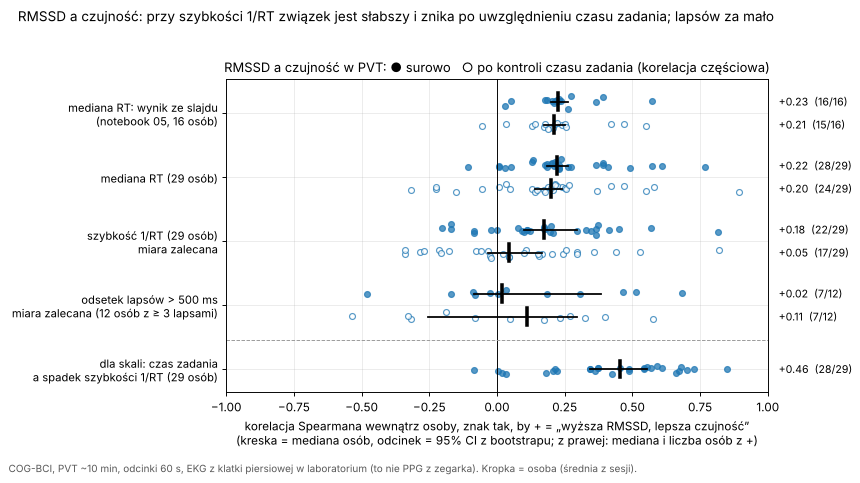

In [15]:
FIG_PATH = Path("../../docs/img/rmssd-vs-vigilance-lapses-response-speed-cogbci.png")
n_all, n_lap = V.subject.nunique(), V[V.rec.isin(lap_recs)].subject.nunique()
rows = [  # (label, RC table, pred, outcome, sign so that + = "higher RMSSD / earlier = better vigilance")
    (f"mediana RT: wynik ze slajdu\n(notebook 05, {V05.subject.nunique()} osób)", RC05, "rmssd", "rt_med_05", -1),
    (f"mediana RT ({n_all} osób)", RC, "rmssd", "rt_med", -1),
    (f"szybkość 1/RT ({n_all} osób)\nmiara zalecana", RC, "rmssd", "speed", +1),
    (f"odsetek lapsów > 500 ms\nmiara zalecana ({n_lap} osób z ≥ 3 lapsami)", RC, "rmssd", "lapse_rate", -1),
    (f"dla skali: czas zadania\na spadek szybkości 1/RT ({n_all} osób)", RC, "t_min", "speed", -1),
]
fig, ax = plt.subplots(figsize=(11, 5.6))
rng = np.random.default_rng(3)
for i, (lab, rc, a, b, sgn) in enumerate(rows):
    for col, off, fc in (("r_raw", -0.18, "tab:blue"), ("r_partial", 0.18, "white")):
        if a == "t_min" and col == "r_partial":
            continue
        v = sgn * to_person(rc, col).loc[(a, b)].dropna().values
        lo, hi = boot_median_ci(v)
        y = i + (0 if a == "t_min" else off)
        ax.plot(v, y + rng.normal(0, 0.035, len(v)), "o", ms=5, mec="tab:blue", mfc=fc, alpha=0.75)
        ax.plot([lo, hi], [y, y], color="k", lw=1.5)
        ax.plot([np.median(v)] * 2, [y - 0.13, y + 0.13], color="k", lw=3)
        ax.text(1.02, y, f"{np.median(v):+.2f}  ({(v > 0).sum()}/{len(v)})", va="center", fontsize=9,
                transform=ax.get_yaxis_transform())
ax.axvline(0, color="k", lw=0.8)
ax.axhline(3.55, color="0.6", lw=0.8, ls="--")
ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=9.5); ax.invert_yaxis()
ax.set_xlim(-1, 1)
ax.set_xlabel("korelacja Spearmana wewnątrz osoby, znak tak, by + = „wyższa RMSSD, lepsza czujność”\n"
              "(kreska = mediana osób, odcinek = 95% CI z bootstrapu; z prawej: mediana i liczba osób z +)")
ax.set_title("RMSSD a czujność w PVT: ● surowo   ○ po kontroli czasu zadania (korelacja częściowa)", fontsize=11)
fig.suptitle("RMSSD a czujność: przy szybkości 1/RT związek jest słabszy i znika po uwzględnieniu czasu zadania; lapsów za mało",
             fontsize=11.5, x=0.02, ha="left")
fig.text(0.01, 0.005, "COG-BCI, PVT ~10 min, odcinki 60 s, EKG z klatki piersiowej w laboratorium (to nie PPG z zegarka). "
         "Kropka = osoba (średnia z sesji).", fontsize=8.5, color="0.35")
plt.tight_layout(rect=(0, 0.03, 0.93, 0.96))
if FIG_PATH.parent.exists():
    fig.savefig(FIG_PATH, dpi=85)
    print(FIG_PATH.name, f"{FIG_PATH.stat().st_size / 1024:.0f} kB")
plt.show()

## 8. Wnioski

Dane: 29 osób, 77 z 87 nagrań PVT po kontroli jakości, 743 odcinki po 60 s. Stary wynik odtworzony dokładnie
(16 osób, 41 nagrań, 393 odcinki, mediana r = −0,23, 16/16).

**Najważniejsze.** Zdanie „RMSSD niesie własną informację o czujności (r = −0,23, ujemne u 16 z 16 osób)” **nie przetrwa**
w tej formie. Na mierze zalecanej przez Basnera i Dingesa, szybkości 1/RT, związek jest słabszy (mediana r = +0,18,
95% CI 0,10–0,30, zgodny kierunek u 22 z 29 osób) i **znika po uwzględnieniu czasu zadania** (korelacja częściowa
+0,05, CI −0,03–0,17, 17/29, p = 0,21). Na lapsach nie da się go sprawdzić: lapsów jest za mało.

**Szczegóły (mediana r po osobach, 95% CI z bootstrapu, liczba osób ze znakiem oczekiwanym).**
- **Mediana RT (stara miara):** −0,22 (CI −0,26 do −0,19), 28/29; po kontroli czasu −0,20 (CI −0,24 do −0,14), 24/29.
  Tu związek zostaje także poza czasem zadania, ale: (a) to miara, którą Basner i Dinges odradzają, (b) przy średnim RT
  jest słabszy (−0,17, a po kontroli czasu −0,11, CI −0,23 do 0,09), więc wynik zależy od tego, czym streszczamy minutę,
  (c) „16 z 16” to liczba po uśrednieniu sesji danej osoby; w pojedynczych nagraniach kierunek był ujemny w 26 z 41
  (wszystkie 29 osób: 53 z 77).
- **Szybkość 1/RT:** surowo +0,18 (22/29; w nagraniach 50/77), bez trendu liniowego +0,15 (CI 0,02–0,24, 20/29, p = 0,04
  bez korekty), częściowa +0,05 (17/29). Dwie metody usuwania czasu dają różne wyniki, a żadna nie przechodzi korekty
  na całą tabelę, więc „RMSSD ponad czas zadania” nie ma solidnego oparcia.
- **Odsetek lapsów (> 500 ms):** liczony tylko u 12 osób (19 nagrań z ≥ 3 lapsami); lapsy są w 17% odcinków, a 26 z 87 nagrań
  nie ma żadnego. Surowo −0,02 (CI −0,39 do 0,09, 7/12), częściowa −0,11 (CI −0,30 do 0,25). To brak mocy, a nie dowód braku związku.
- **Czas zadania jest silniejszy od wszystkiego innego:** szybkość 1/RT spada z czasem u 28 z 29 osób (r = −0,46,
  CI −0,56 do −0,34), RMSSD spada u 22 z 29 (r = −0,24), tętno rośnie u 24 z 29 (r = +0,34). Surowa korelacja RMSSD
  z szybkością w dużej części odbija więc wspólny trend w czasie.
- **Tętno i wskaźniki EEG** (wyrazistość alfy, alfa O1/O2, (θ+α)/β) a 1/RT i lapsy: nic, co przetrwałoby korektę
  (najmocniejsze: alfa O1/O2 a 1/RT surowo −0,13, 21/29, p = 0,016 bez korekty; po kontroli czasu −0,08, p = 0,14).

**Wielokrotne porównania.** Rodzina główna (RMSSD × {1/RT, lapsy} × {surowo, częściowa}, 4 testy, Holm):
przechodzi tylko surowa korelacja z 1/RT (p Holma = 0,001); częściowa z 1/RT p Holma = 0,64, lapsy 0,76.
W całej tabeli (97 testów, Holm) przechodzą: surowa RMSSD a 1/RT (0,034), RMSSD a mediana RT surowo (< 0,001)
i trendy czasu. Korelacja częściowa RMSSD z medianą RT ma p Holma = 0,13.

**Zdanie na slajd (poprawione):** „W 10-minutowym teście czujności zmienność rytmu serca (RMSSD) i szybkość reakcji spadają
razem (r = 0,18, ten kierunek u 22 z 29 osób), ale głównie dlatego, że obie zmieniają się z czasem zadania; ponad czas
zadania RMSSD nie dodaje informacji.” Jeśli brak miejsca: „HRV zmienia się z czasem zadania tak jak czujność, ale jej nie mierzy.”

**PVT.mat.** Wszystkie 87 plików `behavioral/PVT.mat` w COG-BCI zawierają zachowanie z nagrania `sub-29` S3 (sekcja 2).
Wyniki opierające się na nich są błędne; warto zgłosić to autorom zbioru (Zenodo 7413650).

**Ograniczenia.**
- EKG z elektrod na klatce piersiowej w laboratorium to **nie jest** PPG z nadgarstka. Zegarek da gorsze odstępy R–R,
  zwłaszcza w ruchu, więc w produkcie związek będzie co najwyżej słabszy.
- Wyspani uczestnicy, 10 minut PVT: mało lapsów i krótki spadek czujności. Basner i Dinges opisują czułość miar przy braku snu;
  tutaj efekt jest mały i test lapsów nie ma mocy.
- Odcinki 60 s: ok. 9 prób i ok. 10 punktów na nagranie, więc pojedyncze korelacje są bardzo niepewne; RMSSD z 60 s
  to dolna granica sensownej długości okna.
- Czas zadania kontrolujemy liniowo (lub rangowo); nieliniowy przebieg w czasie mógłby zostawić resztę wspólnego trendu,
  co raczej zawyża niż zaniża korelację z RMSSD.
- Wyniki dotyczą zmęczenia i czujności w zadaniu monotonnym; nic tu nie mówi o stresie ani obciążeniu.